# Taller 2 - Churn FinAlpes

Ciencia de Datos Aplicada (MINE-4101) - 2026-20

Integrantes: Sebastián Rodríguez, 

## 0. Librerías y datos

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
%matplotlib inline

In [2]:
df = pd.read_csv("churn.csv")
df.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,418.0,France,Female,46.0,9,0.00,1,1,1,81014.50,1
1,689.0,Germany,Male,67.0,9,157094.78,1,1,1,99490.01,0
2,477.0,Spain,Female,48.0,2,129120.64,1,0,1,26475.79,0
3,573.0,Germany,Female,35.0,9,206868.78,2,0,1,102986.15,0
4,849.0,France,Male,69.0,7,71996.09,1,1,1,139065.94,0


## 1. Entendimiento de los datos

### 1.1 Dimensiones y tipos de variables

In [3]:
print("Registros y columnas:", df.shape)
df.info()

Registros y columnas: (10045, 11)
<class 'pandas.DataFrame'>
RangeIndex: 10045 entries, 0 to 10044
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   credit_score      9795 non-null   float64
 1   country           10045 non-null  str    
 2   gender            10045 non-null  str    
 3   age               9745 non-null   float64
 4   tenure            10045 non-null  int64  
 5   balance           9845 non-null   float64
 6   products_number   10045 non-null  int64  
 7   credit_card       10045 non-null  int64  
 8   active_member     10045 non-null  int64  
 9   estimated_salary  9695 non-null   float64
 10  churn             10045 non-null  int64  
dtypes: float64(4), int64(5), str(2)
memory usage: 863.4 KB


In [4]:
objetivo = "churn"
continuas = ["credit_score", "age", "balance", "estimated_salary"]
discretas = ["tenure", "products_number"]
categoricas = ["country", "gender"]
binarias = ["credit_card", "active_member"]

pd.DataFrame({
    "variable": continuas + discretas + categoricas + binarias + [objetivo],
    "tipo": (["Continua"] * len(continuas) + ["Discreta"] * len(discretas)
             + ["Categórica"] * len(categoricas) + ["Binaria"] * len(binarias) + ["Binaria (objetivo)"]),
}).set_index("variable").join(df.dtypes.rename("dtype_pandas"))

,tipo,dtype_pandas
variable,,
credit_score,Continua,float64
age,Continua,float64
balance,Continua,float64
estimated_salary,Continua,float64
tenure,Discreta,int64
products_number,Discreta,int64
country,Categórica,str
gender,Categórica,str
credit_card,Binaria,int64


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
credit_score,9795.0,650.690148,97.087963,95.0,584.000,652.00,718.000,1200.00
age,9745.0,38.937609,10.734222,-1.0,32.000,37.00,44.000,210.00
tenure,10045.0,5.018915,2.901585,-2.0,3.000,5.00,8.000,25.00
balance,9845.0,76317.500287,62422.434819,0.0,0.000,97042.60,127559.970,250898.09
products_number,10045.0,1.530114,0.581829,1.0,1.000,1.00,2.000,4.00
credit_card,10045.0,0.704530,0.456277,0.0,0.000,1.00,1.000,1.00
active_member,10045.0,0.514684,0.499809,0.0,0.000,1.00,1.000,1.00
estimated_salary,9695.0,100069.014751,57510.689111,-5000.0,51013.655,100130.95,149382.875,199992.48
churn,10045.0,0.203584,0.402683,0.0,0.000,0.00,0.000,1.00


El dataset tiene **10.045 registros y 11 columnas**: 10 variables que describen al cliente y la variable objetivo `churn` (1 = abandonó el banco).

- **Continuas:** credit_score, age, balance y estimated_salary.
- **Discretas:** tenure (años como cliente) y products_number (1 a 4).
- **Categóricas:** country y gender.
- **Binarias:** credit_card y active_member.

En el `describe` ya se ven cosas raras: edades de -1 y 210, credit_score de 95 y 1.200, tenure de -2 y 25 y salarios negativos.

### 1.2 Calidad de los datos

In [6]:
print("Registros duplicados:", df.duplicated().sum())

nulos = pd.DataFrame({"nulos": df.isna().sum(), "porcentaje": (df.isna().mean() * 100).round(2)})
nulos[nulos["nulos"] > 0]

Registros duplicados: 45


,nulos,porcentaje
credit_score,250,2.49
age,300,2.99
balance,200,1.99
estimated_salary,350,3.48


In [7]:
for columna in categoricas:
    print(df[columna].value_counts())
    print()

country
France      5003
Germany     2502
Spain       2475
FRANCE        22
france        17
GERMANY        9
SPAIN          9
germany        6
spain          2
Name: count, dtype: int64

gender
Male      5464
Female    4551
M           16
F           14
Name: count, dtype: int64



In [8]:
rangos = {
    "credit_score": (300, 850), "age": (18, 100), "tenure": (0, 10), "balance": (0, None),
    "products_number": (1, 4), "estimated_salary": (0, None),
}

def fuera_de_rango(datos, columna):
    minimo, maximo = rangos[columna]
    serie = datos[columna].dropna()
    debajo = (serie < minimo).sum() if minimo is not None else 0
    encima = (serie > maximo).sum() if maximo is not None else 0
    return int(debajo + encima)

for columna in rangos:
    minimo, maximo = rangos[columna]
    fuera = df[columna][(df[columna] < minimo) | ((df[columna] > maximo) if maximo is not None else False)]
    if len(fuera) > 0:
        print(f"{columna}: {len(fuera)} fuera de rango -> {sorted(fuera.unique().tolist())}")

credit_score: 4 fuera de rango -> [95.0, 120.0, 999.0, 1200.0]
age: 6 fuera de rango -> [-1.0, 0.0, 5.0, 130.0, 150.0, 210.0]
tenure: 3 fuera de rango -> [-2, 15, 25]
estimated_salary: 3 fuera de rango -> [-5000.0, -120.5, -1.0]


- **Duplicados:** hay 45 filas repetidas.
- **Nulos:** están en 4 columnas y todos por debajo del 5 % (estimated_salary 3,5 %, age 3,0 %, credit_score 2,5 % y balance 2,0 %).
- **Consistencia:** country aparece escrito de 9 formas distintas (France, FRANCE, france...) y gender de 4 (Male/M, Female/F).
- **Validez:** credit_score tiene 4 valores fuera de 300-850, age 6 fuera de 18-100, tenure 3 fuera de 0-10 y estimated_salary 3 negativos.

### 1.3 Limpieza

Se eliminan los duplicados y se unifica la escritura de `country` y `gender`. Las edades, puntajes y antigüedades imposibles se dejan como nulos (recortarlos sería inventar un dato). Los salarios negativos sí se llevan a 0 porque están muy cerca. Los nulos se imputan más adelante, después de dividir los datos, para no filtrar información del conjunto de prueba.

In [9]:
antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Se eliminaron {antes - len(df)} duplicados; quedan {len(df)} registros")

df["country"] = df["country"].str.strip().str.title()
df["gender"] = df["gender"].str.strip().replace({"M": "Male", "F": "Female"})

for columna in ["credit_score", "age", "tenure"]:
    minimo, maximo = rangos[columna]
    df.loc[(df[columna] < minimo) | (df[columna] > maximo), columna] = np.nan
df["estimated_salary"] = df["estimated_salary"].clip(lower=0)

print("Valores fuera de rango después de limpiar:", sum(fuera_de_rango(df, c) for c in rangos))
print(df["country"].value_counts().to_dict(), df["gender"].value_counts().to_dict())
df.isna().sum()[lambda s: s > 0]

Se eliminaron 45 duplicados; quedan 10000 registros
Valores fuera de rango después de limpiar: 0
{'France': 5014, 'Germany': 2509, 'Spain': 2477} {'Male': 5457, 'Female': 4543}


credit_score        254
age                 306
tenure                3
balance             200
estimated_salary    350
dtype: int64

### 1.4 Distribuciones

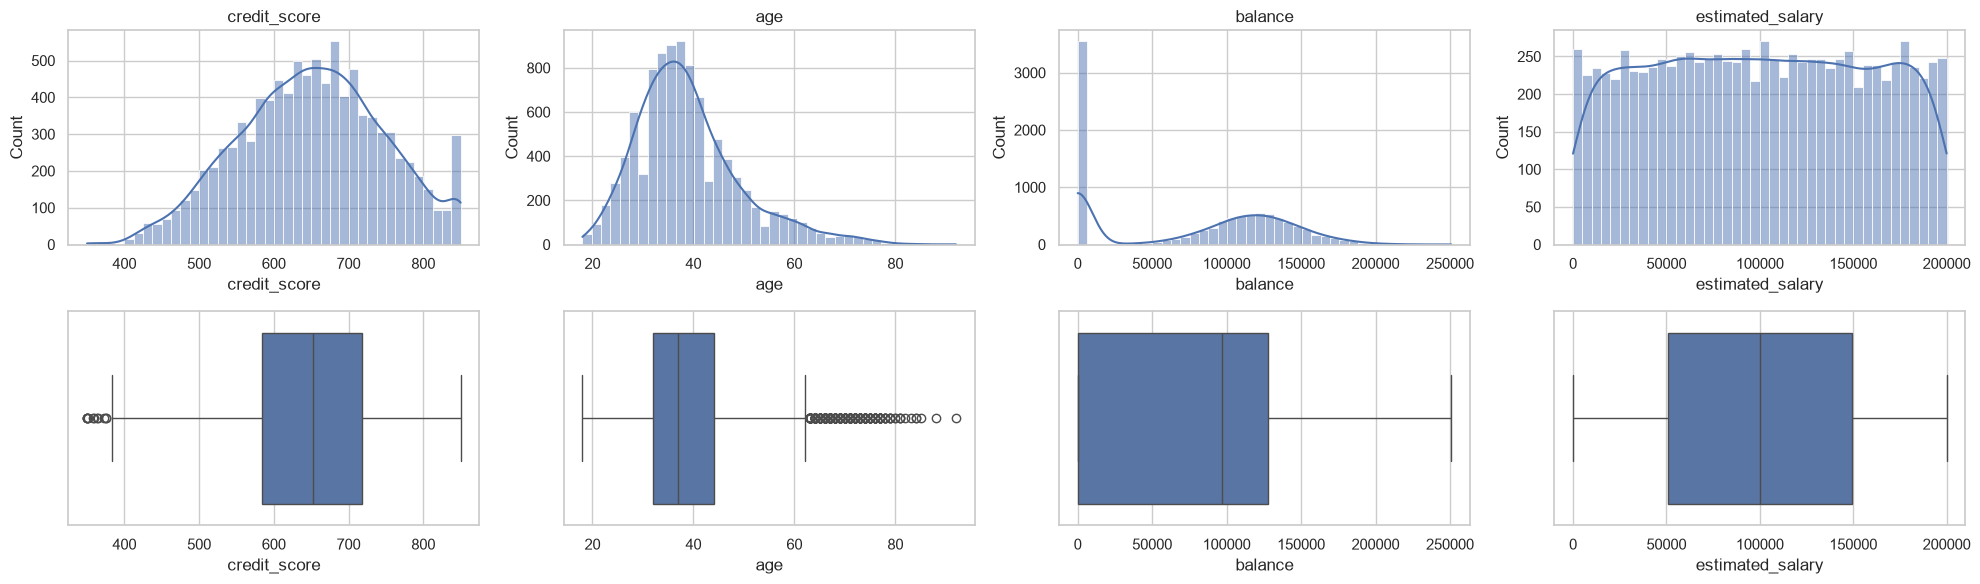

In [10]:
fig, axes = plt.subplots(2, len(continuas), figsize=(5 * len(continuas), 6))
for i, columna in enumerate(continuas):
    sns.histplot(df[columna], bins=40, kde=True, ax=axes[0, i])
    axes[0, i].set_title(columna)
    sns.boxplot(x=df[columna], ax=axes[1, i])
plt.tight_layout()
plt.show()

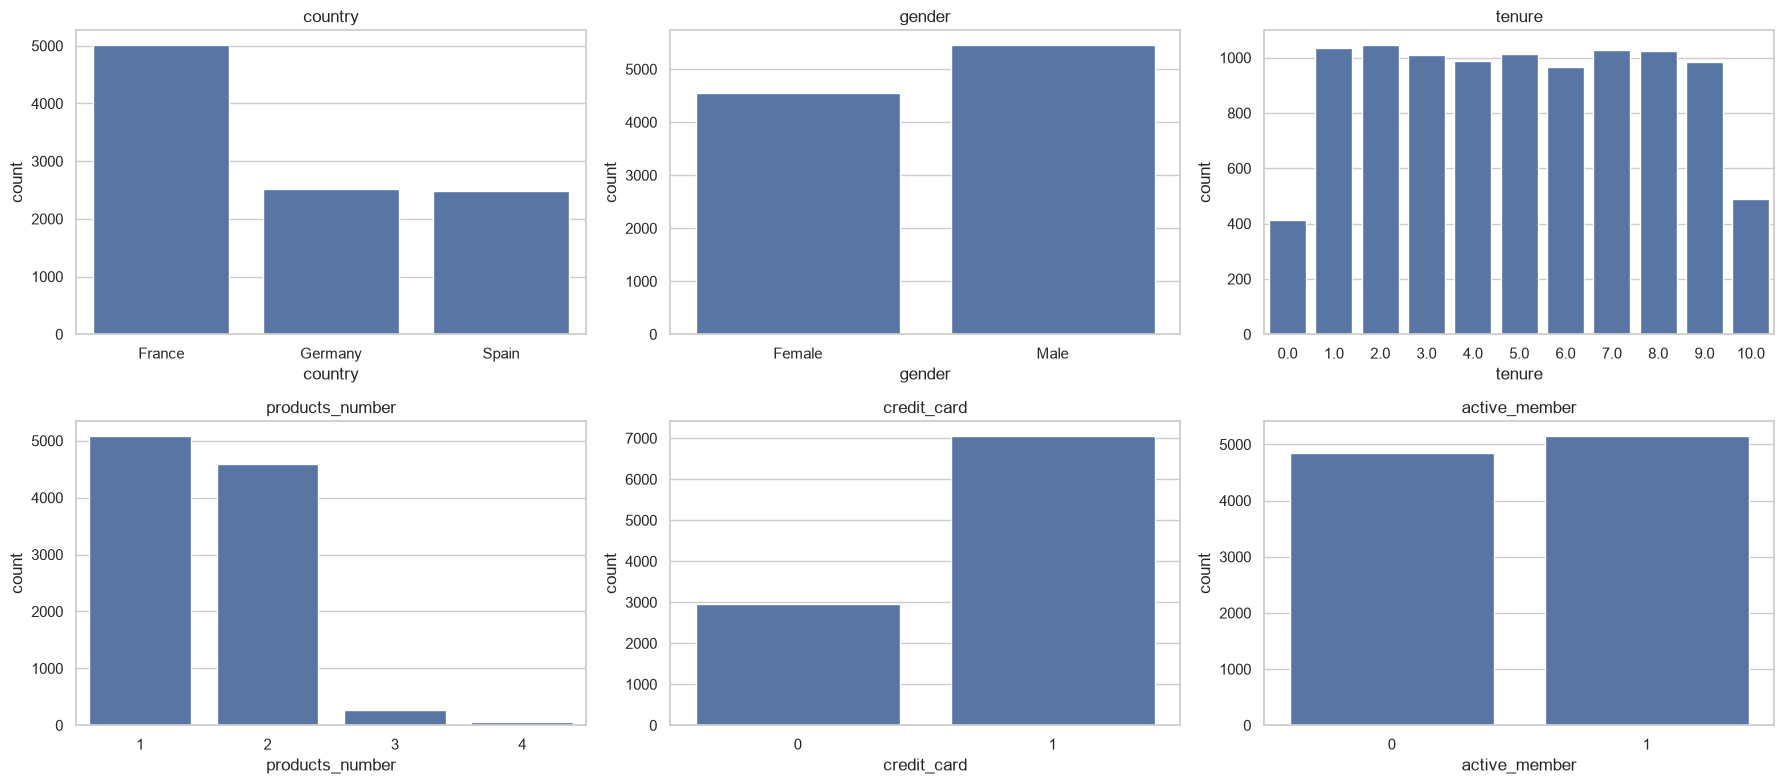

In [11]:
barras = categoricas + discretas + binarias
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, columna in zip(axes.flat, barras):
    sns.countplot(x=columna, data=df, ax=ax, order=sorted(df[columna].dropna().unique()))
    ax.set_title(columna)
plt.tight_layout()
plt.show()

- **age** tiene sesgo a la derecha (asimetría 1,5): la mayoría de los clientes tiene entre 32 y 44 años.
- **balance** es bimodal: el 35,6 % de los clientes tiene saldo 0 y el resto se agrupa alrededor de 120 mil.
- **credit_score** es casi simétrico, con un pico en 850, el máximo de la escala.
- **estimated_salary** es prácticamente uniforme entre 0 y 200 mil.
- En las categóricas, la mitad de los clientes es de Francia y la otra mitad se reparte entre Alemania y España. Casi todos tienen 1 o 2 productos: 3 y 4 productos son muy raros (2,7 % y 0,6 %). El 70 % tiene tarjeta de crédito y el 51 % es miembro activo.

### 1.5 Variable objetivo

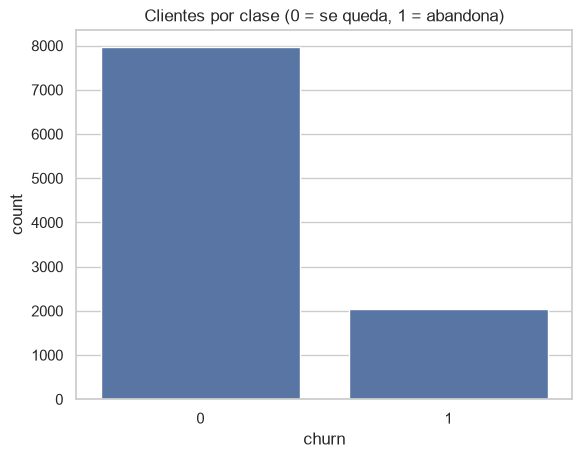

churn
0    7963
1    2037
Name: count, dtype: int64
churn
0    0.7963
1    0.2037
Name: proportion, dtype: float64


In [12]:
sns.countplot(x=objetivo, data=df)
plt.title("Clientes por clase (0 = se queda, 1 = abandona)")
plt.show()

print(df[objetivo].value_counts())
print(df[objetivo].value_counts(normalize=True).round(4))

El **20,4 % de los clientes abandonó** (2.037 de 10.000). Las clases están desbalanceadas: hay unos 4 clientes que se quedan por cada uno que se va. Por eso la exactitud no sirve para evaluar, porque un modelo que diga siempre "no abandona" acierta casi el 80 %. Hay que mirar recall, precisión, F1 y AUC, y estratificar al dividir los datos.

La tasa del dataset (20 %) está por encima del 15 % de referencia del enunciado. Esto hay que tenerlo en cuenta al llevar los resultados al banco de 20.000 clientes.

### 1.6 Churn según cada variable

Tasa de abandono por grupo y comparación de las variables continuas entre los que se quedan y los que se van.

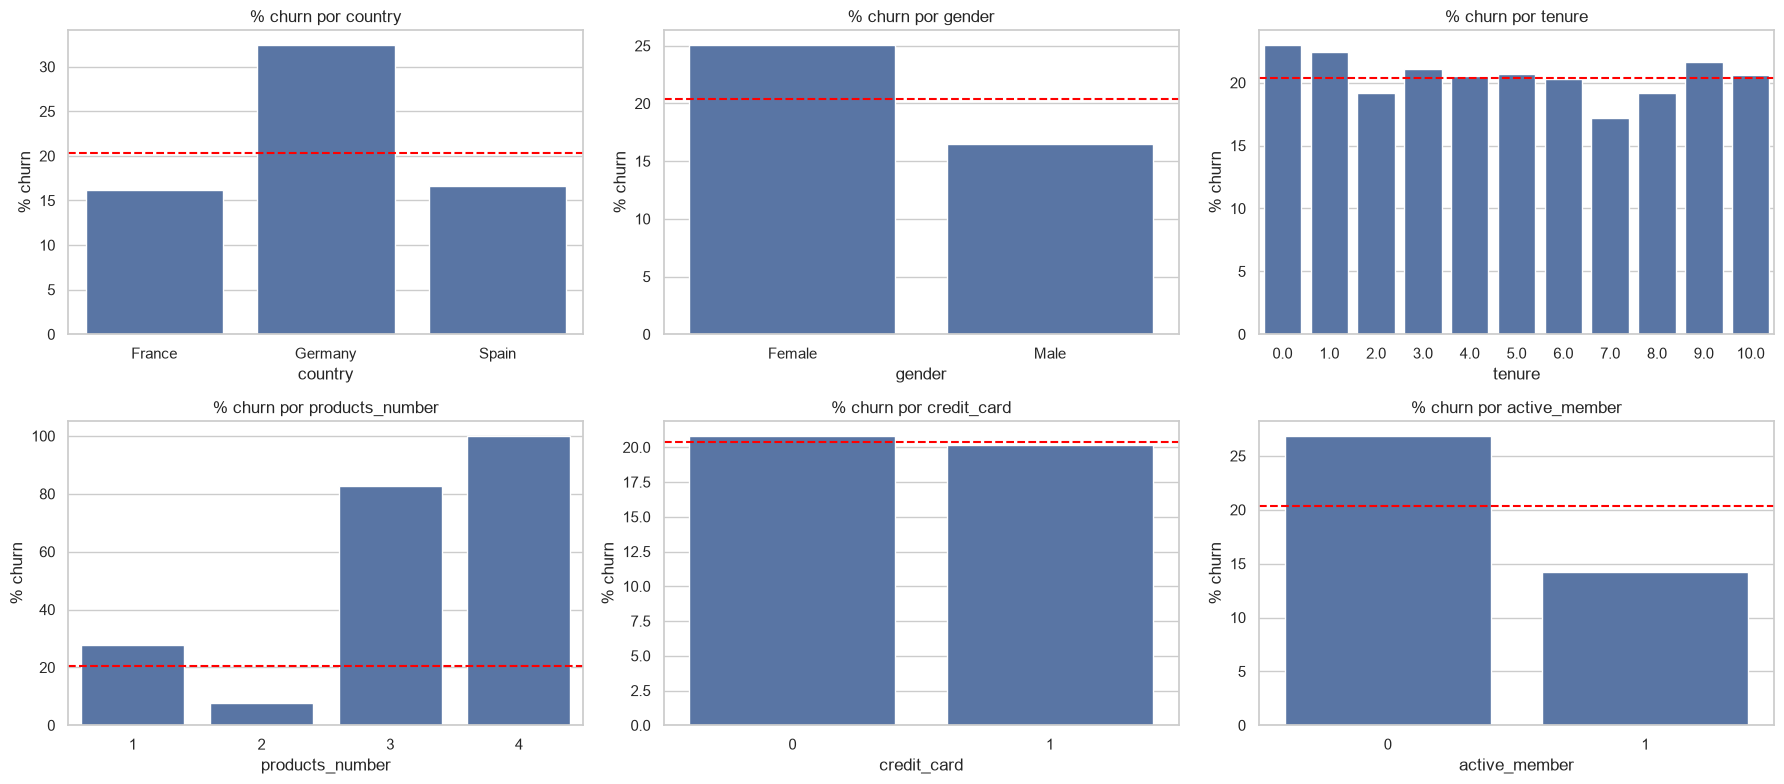

In [13]:
tasa_global = df[objetivo].mean()
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, columna in zip(axes.flat, barras):
    tasa = df.groupby(columna)[objetivo].mean().mul(100)
    sns.barplot(x=tasa.index, y=tasa.values, ax=ax)
    ax.axhline(tasa_global * 100, color="red", linestyle="--")
    ax.set_title(f"% churn por {columna}")
    ax.set_ylabel("% churn")
plt.tight_layout()
plt.show()

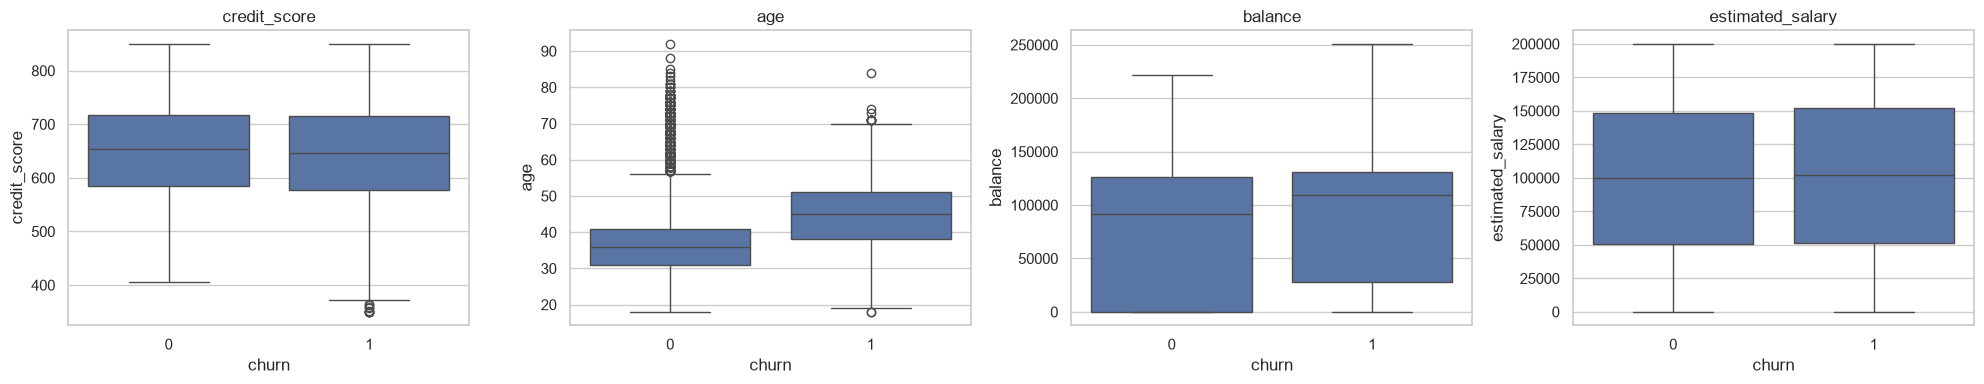

,credit_score,age,balance,estimated_salary
churn,,,,
0,654.0,36.0,91835.2,99645.0
1,646.0,45.0,109154.0,101954.8


In [14]:
fig, axes = plt.subplots(1, len(continuas), figsize=(5 * len(continuas), 4))
for ax, columna in zip(axes, continuas):
    sns.boxplot(x=objetivo, y=columna, data=df, ax=ax)
    ax.set_title(columna)
plt.tight_layout()
plt.show()

df.groupby(objetivo)[continuas].median().round(1)

In [15]:
df["grupo_edad"] = pd.cut(df["age"], bins=[17, 30, 40, 50, 60, 100], labels=["18-30", "31-40", "41-50", "51-60", "60+"])
print(df.groupby("grupo_edad", observed=True)[objetivo].agg(["mean", "count"]).round(3))
df = df.drop(columns="grupo_edad")

             mean  count
grupo_edad              
18-30       0.077   1910
31-40       0.123   4304
41-50       0.338   2252
51-60       0.560    782
60+         0.247    446


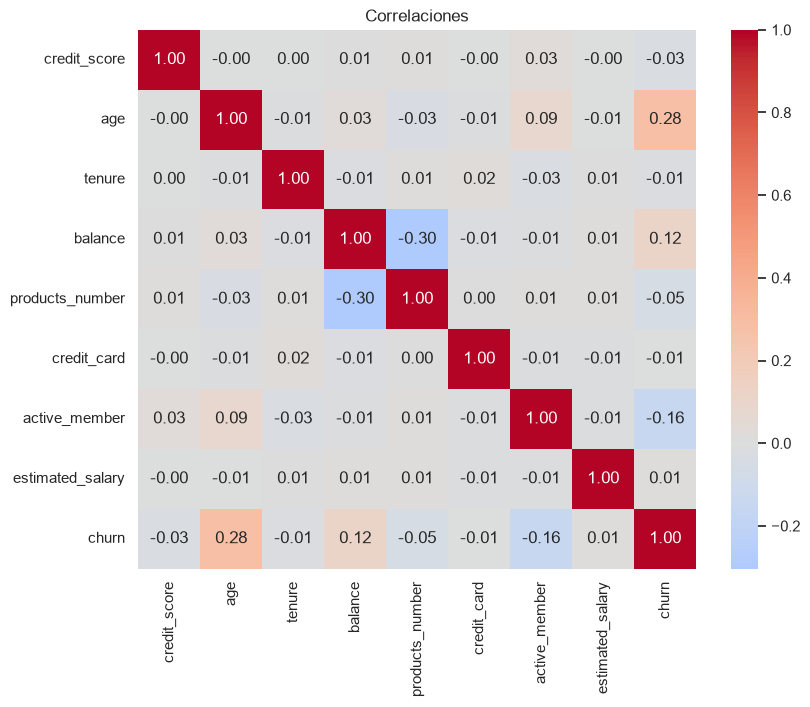

In [16]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlaciones")
plt.show()

Las variables que más separan a los que se van de los que se quedan son:

- **Edad:** es la más fuerte (correlación 0,27). El churn sube de 8 % en los menores de 30 a 34 % entre 41 y 50 años y a 56 % entre 51 y 60. La mediana de edad de los que abandonan es 45 años, contra 36 de los que se quedan.
- **Número de productos:** con 2 productos el churn es solo de 7,6 %, con 1 producto es de 28 % y con 3 o 4 se va casi todo el mundo (83 % y 100 %), aunque son pocos clientes.
- **País:** en Alemania el churn es de 32 %, el doble que en Francia y España (≈16 %).
- **Miembro activo:** los inactivos abandonan casi el doble que los activos (27 % contra 14 %).
- **Género:** las mujeres abandonan más que los hombres (25 % contra 17 %).
- **Saldo:** los clientes con saldo abandonan más (24 %) que los que tienen saldo 0 (14 %).

Las que **casi no influyen** son credit_score, estimated_salary, tenure y credit_card: su churn es parecido en todos los grupos y la correlación con churn es cercana a 0.

### Conclusiones de la sección 1

Después de la limpieza quedan **10.000 clientes**. No hay duplicados, las categorías están unificadas y los valores imposibles se convirtieron en nulos. Quedan nulos en credit_score, age, tenure, balance y estimated_salary, que se imputan en la sección 2 con la mediana del conjunto de entrenamiento.

El perfil de mayor riesgo es un cliente mayor de 40 años, de Alemania, inactivo, con un solo producto (o con 3 o más) y con saldo en la cuenta. Las relaciones no son lineales: la edad sube y baja, y el número de productos tiene forma de U. Por eso conviene probar modelos de árboles, además de uno lineal como referencia.

## 2. Modelos

Se prueban tres modelos:
- **Regresión logística**, como línea base.
- **Random Forest**.
- **Gradient Boosting**.

En la sección 1 vimos que la edad y el número de productos no tienen una relación lineal con el churn, así que se espera que los modelos de árboles funcionen mejor.

### 2.1 Preparación y división de los datos

Se usan todas las variables. country y gender se pasan a dummies. Los datos se dividen en 60 % entrenamiento, 20 % validación y 20 % prueba, de forma estratificada. Los nulos se imputan con la mediana del entrenamiento y después se escala.

In [17]:
datos = pd.get_dummies(df, columns=categoricas, drop_first=True, dtype=int)
columnas = datos.columns.drop(objetivo).tolist()
X = datos[columnas]
y = datos[objetivo]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

medianas = X_train.median()
X_train, X_val, X_test = X_train.fillna(medianas), X_val.fillna(medianas), X_test.fillna(medianas)

escalador = StandardScaler()
X_train_esc = pd.DataFrame(escalador.fit_transform(X_train), columns=columnas, index=X_train.index)
X_val_esc = pd.DataFrame(escalador.transform(X_val), columns=columnas, index=X_val.index)
X_test_esc = pd.DataFrame(escalador.transform(X_test), columns=columnas, index=X_test.index)

print("Columnas:", columnas)
pd.DataFrame({
    "registros": [len(s) for s in (y_train, y_val, y_test)],
    "proporcion_churn": [round(float(s.mean()), 4) for s in (y_train, y_val, y_test)],
}, index=["Entrenamiento", "Validación", "Prueba"])

Columnas: ['credit_score', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary', 'country_Germany', 'country_Spain', 'gender_Male']


,registros,proporcion_churn
Entrenamiento,6000,0.2038
Validación,2000,0.2035
Prueba,2000,0.2035


### 2.2 Búsqueda de hiperparámetros

Se usa `GridSearchCV` con validación cruzada de 5 folds sobre el entrenamiento. Los modelos se comparan por **AUC** y no por F1: lo que importa es que el modelo ordene bien a los clientes por riesgo. El umbral de corte (a cuántos clientes contactar) se decide en la sección 5, según la ganancia.

In [18]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tiempos = {}

def buscar(nombre, modelo, rejilla):
    inicio = time.time()
    busqueda = GridSearchCV(modelo, rejilla, cv=skf, scoring="roc_auc", n_jobs=-1)
    busqueda.fit(X_train_esc, y_train)
    tiempos[nombre] = time.time() - inicio
    print("Mejor combinación:", busqueda.best_params_)
    print(f"AUC de validación cruzada: {busqueda.best_score_:.3f} | tiempo: {tiempos[nombre]:.0f} s")
    return busqueda

In [19]:
busqueda_logistica = buscar("Regresión logística", LogisticRegression(max_iter=1000),
                            {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]})

Mejor combinación: {'C': 0.1, 'class_weight': 'balanced'}
AUC de validación cruzada: 0.761 | tiempo: 4 s


In [20]:
busqueda_rf = buscar("Random Forest", RandomForestClassifier(random_state=42),
                     {"n_estimators": [200, 400], "max_depth": [5, 10, None], "min_samples_leaf": [1, 5, 20],
                      "class_weight": [None, "balanced"]})
pd.DataFrame(busqueda_rf.cv_results_).sort_values("mean_test_score", ascending=False)[
    ["param_n_estimators", "param_max_depth", "param_min_samples_leaf", "param_class_weight", "mean_test_score"]
].head(5).round(3)

Mejor combinación: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 200}
AUC de validación cruzada: 0.865 | tiempo: 7 s


,param_n_estimators,param_max_depth,param_min_samples_leaf,param_class_weight,mean_test_score
24,200,10,1,balanced,0.865
25,400,10,1,balanced,0.865
7,400,10,1,NaN,0.864
26,200,10,5,balanced,0.864
27,400,10,5,balanced,0.864


In [21]:
busqueda_gb = buscar("Gradient Boosting", GradientBoostingClassifier(random_state=42),
                     {"n_estimators": [100, 300], "learning_rate": [0.05, 0.1], "max_depth": [2, 3, 4]})
pd.DataFrame(busqueda_gb.cv_results_).pivot_table(index=["param_max_depth", "param_n_estimators"],
                                                  columns="param_learning_rate", values="mean_test_score").round(3)

Mejor combinación: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
AUC de validación cruzada: 0.867 | tiempo: 3 s


param_learning_rate                  0.05   0.10
param_max_depth param_n_estimators              
2               100                 0.856  0.861
                300                 0.863  0.862
3               100                 0.865  0.867
                300                 0.866  0.861
4               100                 0.865  0.865
                300                 0.864  0.856

Mejores combinaciones (AUC de validación cruzada):

- **Regresión logística:** C = 0,1 con `class_weight="balanced"` (0,761).
- **Random Forest:** 200 árboles, `max_depth=10`, `min_samples_leaf=1` y `class_weight="balanced"` (0,865). Las primeras cinco combinaciones quedan entre 0,864 y 0,865, así que el modelo es poco sensible a la rejilla. Lo que más pesa es limitar la profundidad a 10.
- **Gradient Boosting:** 100 árboles, `learning_rate=0,1` y `max_depth=3` (0,867). Con más árboles y una tasa alta empieza a empeorar (0,856 con 300 árboles, profundidad 4 y tasa 0,1).

Los dos modelos de árboles le sacan unos 10 puntos de AUC a la regresión logística, como se esperaba. Todas las búsquedas tardan menos de 10 segundos.

### 2.3 Selección del modelo

Se comparan los tres modelos en entrenamiento y validación. El conjunto de prueba se deja para la sección 3.

In [22]:
modelos = {
    "Regresión logística": busqueda_logistica.best_estimator_,
    "Random Forest": busqueda_rf.best_estimator_,
    "Gradient Boosting": busqueda_gb.best_estimator_,
}

filas = {}
for nombre, modelo in modelos.items():
    prob_train = modelo.predict_proba(X_train_esc)[:, 1]
    prob_val = modelo.predict_proba(X_val_esc)[:, 1]
    filas[nombre] = {"AUC train": roc_auc_score(y_train, prob_train), "AUC val": roc_auc_score(y_val, prob_val),
                     "AP train": average_precision_score(y_train, prob_train), "AP val": average_precision_score(y_val, prob_val),
                     "tiempo búsqueda (s)": tiempos[nombre]}
seleccion = pd.DataFrame(filas).T
seleccion["brecha AUC"] = seleccion["AUC train"] - seleccion["AUC val"]
mejor = seleccion["AUC val"].idxmax()
print("Modelo con mayor AUC de validación:", mejor)
seleccion.round(3)

Modelo con mayor AUC de validación: Gradient Boosting


,AUC train,AUC val,AP train,AP val,tiempo búsqueda (s),brecha AUC
Regresión logística,0.764,0.762,0.456,0.441,4.372,0.002
Random Forest,0.973,0.840,0.921,0.649,7.328,0.134
Gradient Boosting,0.895,0.848,0.765,0.679,3.042,0.047


**Se elige el Gradient Boosting.** Tiene el mayor AUC (0,848) y el mayor AP (0,679) en validación.

- El **Random Forest** queda cerca en validación (AUC 0,840), pero sobreajusta bastante: en entrenamiento tiene 0,973, una brecha de 0,13. El Gradient Boosting baja solo 0,05.
- La **regresión logística** no sobreajusta (0,764 contra 0,762), pero se queda corta: al ser lineal no capta la forma en U de products_number ni el pico de churn entre 50 y 60 años.

## 3. Resultados (métricas)

## 4. Interpretación del modelo

## 5. Valor para el negocio

Datos del enunciado: banco de 20.000 clientes, la campaña retiene al 30% de los que se iban a ir, se paga por cada cliente contactado, ingreso anual por cliente entre $500.000 y $900.000 y deserción de referencia de 15%.

## 6. Conclusiones y recomendación

## 7. Uso de IA